# Cartpole Swing-Up via Direct Collocation

## The Problem

Imagine a cart on a frictionless rail with a rigid pole attached by a hinge. The pole starts **hanging straight down** (the stable equilibrium), and we want it to end **balanced straight up** (the unstable equilibrium), with the cart at rest and the pole at rest. This is the classic **cartpole swing-up** problem — a favorite benchmark in optimal control because it's nonlinear, underactuated (one input, four states), and requires exploiting the system's natural dynamics rather than just "pushing hard."

### State and Control

$$
x = \begin{bmatrix} p \\ \theta \\ v \\ \omega \end{bmatrix}, \qquad u = F
$$

| Symbol | Meaning | Units |
|---|---|---|
| `p`      | cart position along the rail   | m |
| `θ`      | pole angle (0 = upright)       | rad |
| `v`      | cart velocity                  | m/s |
| `ω`      | pole angular velocity          | rad/s |
| `F`      | horizontal force on the cart   | N |

### Dynamics

The equations of motion come from a Lagrangian derivation (see any robotics textbook). With `m_c` the cart mass, `m_p` the pole mass, `l` the pole half-length, and `g` gravity:

$$
\dot{p} = v, \qquad \dot{\theta} = \omega
$$

$$
\dot{v} = \frac{F + m_p \sin\theta\,(l\,\omega^2 + g\cos\theta)}{m_c + m_p \sin^2\theta}
$$

$$
\dot{\omega} = \frac{-F\cos\theta - m_p l\,\omega^2 \cos\theta \sin\theta + (m_c + m_p)\,g \sin\theta}{l\,(m_c + m_p \sin^2\theta)}
$$

These are the same equations encoded in the `cartpole_dynamics` function in the notebook.

### Boundary Conditions

$$
x(0) = \begin{bmatrix} 0 \\ \pi \\ 0 \\ 0 \end{bmatrix},
\qquad
x(T) = \begin{bmatrix} 0 \\ 0 \\ 0 \\ 0 \end{bmatrix}
$$

- Start: cart centered, pole hanging down (`θ = π`), everything at rest.
- End: cart centered, pole upright (`θ = 0`), everything at rest.

### Objective

Among all trajectories that satisfy the dynamics and boundary conditions, we want the one that **uses the least control effort**:

$$
\min_{x(\cdot),\,u(\cdot)} \;\; \int_0^T u(t)^2 \, dt
$$

with the control bounded, `|F| ≤ F_max`. This is what we approximate in the NLP as `h · Σ ‖u_k‖²`.

## The Approach — Direct Collocation in Three Steps

### Step 1 — Discretize time

Pick a horizon `T` and split it into `N` intervals of length `h = T/N`. Collect the state at each of the `N+1` nodes into a matrix `X`, and the control on each of the `N` intervals into a matrix `U`. These become the **decision variables** of an optimization problem.

### Step 2 — Enforce dynamics with collocation

At each interval we require the states and controls to satisfy the **Hermite–Simpson collocation defect**:

$$
x_{k+1} - x_k - \tfrac{h}{6}\bigl(f_k + 4 f_{\text{mid}} + f_{k+1}\bigr) = 0
$$

where the midpoint is Hermite-interpolated:

$$
x_{\text{mid}} = \tfrac{1}{2}(x_k + x_{k+1}) + \tfrac{h}{8}(f_k - f_{k+1})
$$

This is a 2nd-order implicit scheme that is far more accurate and far better conditioned than Euler for trajectory optimization. (A separate markdown cell goes into why.)

### Step 3 — Hand it to IPOPT

The whole thing — states, controls, dynamics constraints, boundary conditions, control bounds, and cost — is assembled as a nonlinear program using CasADi's `Opti` stack. IPOPT (an interior-point NLP solver) solves it. The result is the *entire trajectory* — every state and every control — in one shot.





In [ ]:
!pip install casadi matplotlib numpy -q

In [ ]:
import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

def cartpole_dynamics(x, u, params):
    """
    Continuous-time dynamics of a cartpole.
    State x = [p, theta, v, omega]
      p     : cart position
      theta : pole angle (0 = upright)
      v     : cart velocity
      omega : pole angular velocity
    Control u = force on cart
    """
    p, theta, v, omega = x[0], x[1], x[2], x[3]
    F = u[0]

    mc, mp, l, g = params['mc'], params['mp'], params['l'], params['g']

    s = ca.sin(theta)
    c = ca.cos(theta)
    denom = mc + mp * s**2

    # Standard cartpole equations of motion
    p_dot     = v
    theta_dot = omega
    v_dot = (F + mp * s * (l * omega**2 + g * c)) / denom
    omega_dot = (-F * c - mp * l * omega**2 * c * s + (mc + mp) * g * s) / (l * denom)

    return ca.vertcat(p_dot, theta_dot, v_dot, omega_dot)

# Direct Collocation for the Cartpole — Why Hermite–Simpson?

## The Big Picture

Direct collocation turns an optimal control problem (OCP) into a **nonlinear program (NLP)** that a standard solver like IPOPT can chew on.

We discretize time into `N` intervals of length `h = T/N`. The decision variables of the NLP are:

- `X ∈ ℝ^{4 × (N+1)}` — the state at each **node** (interval endpoints)
- `U ∈ ℝ^{1 × N}`     — the control on each **interval**

We then add constraints so that this discrete trajectory is *dynamically consistent*: the state must evolve according to

$$
\dot{x} = f(x, u)
$$

## Why Can't We Just Use Euler?

The naive approach is **explicit Euler**:

$$
x_{k+1} = x_k + h \, f(x_k, u_k)
$$

This is simple, but it has two nasty properties for trajectory optimization:

1. **Only 1st-order accurate** — the ODE error scales like `O(h)`. To get a good trajectory you need many nodes, which means a huge NLP.
2. **It fights the optimizer.** Explicit integration assumes you march forward from `x_k`. But IPOPT wants to adjust *all* `X` and `U` at once to minimize cost. Euler forces a causal, forward-only relationship that makes the constraint Jacobian poorly conditioned, and the solver often fails on stiff or unstable systems — like a cartpole swinging up near the upright equilibrium.

## Hermite–Simpson Collocation

Hermite–Simpson is a **2nd-order implicit** method that avoids both problems. Instead of trusting the dynamics at just one endpoint, it uses three samples per interval:

| Sample | Location | Expression |
|---|---|---|
| `f_k`   | left node         | `f(x_k, u_k)` |
| `f_{k+1}` | right node      | `f(x_{k+1}, u_{k+1})` |
| `f_mid` | interval midpoint | `f(x_mid, u_mid)` |

The midpoint state is obtained by a **Hermite cubic interpolation**, which is itself constructed from the endpoint states *and* endpoint derivatives:

$$
x_{\text{mid}} = \tfrac{1}{2}(x_k + x_{k+1}) + \tfrac{h}{8}\bigl(f_k - f_{k+1}\bigr)
$$

$$
u_{\text{mid}} = \tfrac{1}{2}(u_k + u_{k+1})
$$

Then we enforce the **Simpson quadrature** relation on the interval:

$$
\boxed{\; x_{k+1} - x_k - \tfrac{h}{6}\bigl(f_k + 4 f_{\text{mid}} + f_{k+1}\bigr) = 0 \;}
$$

That boxed equation is the *collocation defect*, and it becomes one constraint in the NLP for every interval. In CasADi:

```python
f_k   = f(x_k,  u_k)
f_k1  = f(x_k1, u_k1)
x_mid = 0.5*(x_k + x_k1) + (h/8)*(f_k - f_k1)
f_mid = f(x_mid, 0.5*(u_k + u_k1))

defect = x_k1 - x_k - (h/6)*(f_k + 4*f_mid + f_k1)

In [ ]:
def hermite_simpson_step(x_k, x_k1, u_k, u_k1, h, params):
    """
    Returns the Hermite-Simpson collocation defect for one interval:
        x_{k+1} - x_k - (h/6)*(f_k + 4*f_mid + f_{k+1}) = 0
    where x_mid = (x_k + x_{k+1})/2 + (h/8)*(f_k - f_{k+1})
    """
    f_k   = cartpole_dynamics(x_k,  u_k,   params)
    f_k1  = cartpole_dynamics(x_k1, u_k1,  params)

    # Midpoint state (Hermite interpolation)
    x_mid = 0.5 * (x_k + x_k1) + (h / 8.0) * (f_k - f_k1)
    u_mid = 0.5 * (u_k + u_k1)
    f_mid = cartpole_dynamics(x_mid, u_mid, params)

    # Simpson quadrature defect
    defect = x_k1 - x_k - (h / 6.0) * (f_k + 4.0 * f_mid + f_k1)
    return defect

In [ ]:
def solve_cartpole_swingup(N=50, T=2.0, u_max=40.0):
    params = {'mc': 1.0, 'mp': 0.2, 'l': 0.5, 'g': 9.81}
    nx, nu = 4, 1
    h = T / N

    opti = ca.Opti()

    # Decision variables
    X = opti.variable(nx, N + 1)   # states at nodes
    U = opti.variable(nu, N)       # controls on intervals

    # Boundary conditions: start hanging down, end upright at rest
    x0 = np.array([0.0, np.pi, 0.0, 0.0])
    xf = np.array([0.0, 0.0,  0.0, 0.0])

    opti.subject_to(X[:, 0]  == x0)
    opti.subject_to(X[:, N]  == xf)

    # Dynamics: Hermite-Simpson defects
    for k in range(N):
        defect = hermite_simpson_step(X[:, k], X[:, k+1], U[:, k], U[:, k], h, params)
        opti.subject_to(defect == 0)

    # Control limits
    opti.subject_to(opti.bounded(-u_max, U, u_max))

    # Cost: control effort + a small terminal velocity penalty
    cost = h * ca.sumsqr(U)
    opti.minimize(cost)

    # Solver
    opti.solver('ipopt', {'print_time': False},
                {'max_iter': 3000, 'tol': 1e-8, 'print_level': 5})

    # Initial guess: linear interpolation between x0 and xf
    X_guess = np.outer(x0, np.ones(N + 1)) + \
              np.outer(xf - x0, np.linspace(0, 1, N + 1))
    # Unwrap angle so we go from pi to 0 the "short way" through the swing-up
    X_guess[1, :] = np.linspace(np.pi, 0, N + 1)
    opti.set_initial(X, X_guess)
    opti.set_initial(U, np.zeros((nu, N)))

    sol = opti.solve()

    X_opt = sol.value(X)
    U_opt = sol.value(U)
    return X_opt, U_opt, params, h

X_opt, U_opt, params, h = solve_cartpole_swingup(N=50, T=2.0)
print("Solver status:", "SUCCESS")
print("Final state:", X_opt[:, -1])


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.8.2.

Number of nonzeros in equality constraint Jacobian...:     1308
Number of nonzeros in inequality constraint Jacobian.:       50
Number of nonzeros in Lagrangian Hessian.............:      603

Total number of variables............................:      254
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:      208
Total number of inequality c

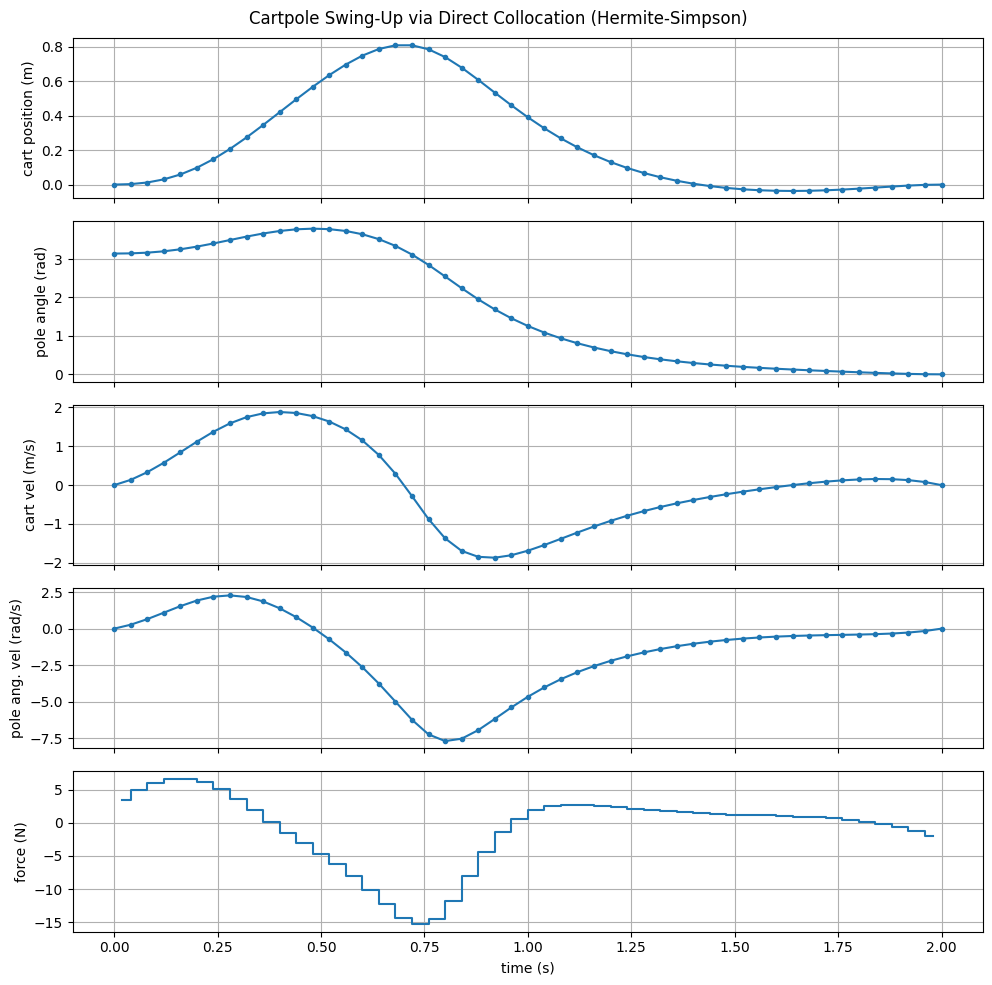

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
t_nodes = np.arange(X_opt.shape[1]) * h
t_ctrl  = (np.arange(U_opt.shape[0]) + 0.5) * h

labels = ['cart position (m)', 'pole angle (rad)', 'cart vel (m/s)', 'pole ang. vel (rad/s)']
for i in range(4):
    axes[i].plot(t_nodes, X_opt[i, :], '-o', ms=3)
    axes[i].set_ylabel(labels[i])
    axes[i].grid(True)

# U_opt is 1D, so we plot it directly without indexing the first dimension
axes[4].step(t_ctrl, U_opt, where='mid')
axes[4].set_ylabel('force (N)')
axes[4].set_xlabel('time (s)')
axes[4].grid(True)

plt.suptitle('Cartpole Swing-Up via Direct Collocation (Hermite-Simpson)')
plt.tight_layout()
plt.show()

In [ ]:
def animate_cartpole(X, h, params, fps=30):
    p   = X[0, :]
    th  = X[1, :]
    l   = params['l']

    # Interpolate to a smoother frame count
    T_end = h * (X.shape[1] - 1)
    n_frames = int(T_end * fps)
    t_smooth = np.linspace(0, T_end, n_frames)
    p_s   = np.interp(t_smooth, np.arange(X.shape[1]) * h, p)
    th_s  = np.interp(t_smooth, np.arange(X.shape[1]) * h, th)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.grid(True)

    cart_w, cart_h = 0.4, 0.2
    cart = plt.Rectangle((-cart_w/2, -cart_h/2), cart_w, cart_h, fc='steelblue')
    ax.add_patch(cart)
    pole, = ax.plot([], [], 'o-', lw=4, color='crimson', markersize=8)

    def init():
        pole.set_data([], [])
        return cart, pole

    def update(i):
        cart.set_xy((p_s[i] - cart_w/2, -cart_h/2))
        # Pole tip position
        xt = p_s[i] + 2 * l * np.sin(th_s[i])
        yt = 0 + 2 * l * np.cos(th_s[i])
        pole.set_data([p_s[i], xt], [0, yt])
        return cart, pole

    anim = animation.FuncAnimation(fig, update, frames=n_frames,
                                   init_func=init, blit=True, interval=1000/fps)
    plt.close(fig)
    return anim

anim = animate_cartpole(X_opt, h, params, fps=30)
HTML(anim.to_jshtml())